# Almeida K.K.O. (IT25103191) – Progress Review I
## Preprocessing Technique: Normalization / Scaling
**Group ID:** 2026-Y2-S1-MLB-B11G2-05 &nbsp;|&nbsp; **Member:** Almeida K.K.O. &nbsp;|&nbsp; **Index No.:** IT25103191
**Module:** Artificial Intelligence and Machine Learning
**Dataset:** UCI *Letter Recognition* Data Set (20,000 instances, 16 numeric attributes + 1 categorical target `lettr`)



## 1. Technique Overview: Normalization / Scaling

Feature scaling rescales numeric attributes onto a comparable range so that no single feature
dominates a model purely because of its units or magnitude. The two most common approaches:

- **Standardization (Z-score scaling, `StandardScaler`):** transforms a feature to have mean 0 and
  standard deviation 1: `z = (x − μ) / σ`. Preferred when a feature is roughly Gaussian, or when the
  downstream algorithm assumes standardized inputs (PCA, linear/logistic regression, SVM).
- **Min-Max scaling (`MinMaxScaler`):** rescales a feature into a fixed range, typically `[0, 1]`:
  `x' = (x − min) / (max − min)`. Preferred when the algorithm needs bounded inputs (e.g. neural
  network input layers) or when the distribution is not Gaussian.

Scaling matters most for **distance-based** algorithms (KNN, SVM, K-Means) and **gradient-based**
optimizers, since a feature on a larger numeric scale would otherwise dominate the distance
calculation or gradient step irrespective of its actual predictive importance.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option('display.max_columns', 20)
sns.set_style('whitegrid')

COLUMN_NAMES = ['lettr', 'x-box', 'y-box', 'width', 'high', 'onpix', 'x-bar', 'y-bar',
                'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x-ege', 'xegvy', 'y-ege', 'yegvx']

df = pd.read_csv('../data/raw/letter-recognition.data', header=None, names=COLUMN_NAMES)
feature_cols = [c for c in df.columns if c != 'lettr']
print("Dataset shape:", df.shape)
df[feature_cols].describe().T[['mean', 'std', 'min', 'max']]


Dataset shape: (20000, 17)


,mean,std,min,max
x-box,4.02355,1.913212,0.0,15.0
y-box,7.03550,3.304555,0.0,15.0
width,5.12185,2.014573,0.0,15.0
high,5.37245,2.261390,0.0,15.0
onpix,3.50585,2.190458,0.0,15.0
x-bar,6.89760,2.026035,0.0,15.0
y-bar,7.50045,2.325354,0.0,15.0
x2bar,4.62860,2.699968,0.0,15.0
y2bar,5.17865,2.380823,0.0,15.0
xybar,8.28205,2.488475,0.0,15.0


## 2. Justification for This Technique

All 16 features are already bounded to the integer range 0–15, which might suggest scaling is
unnecessary. However, the table above shows the **standard deviations differ noticeably** across
features (e.g. `x-box` has a much smaller spread than `x2bar` or `xy2br`), meaning the features do
**not** occupy the range 0–15 with equal density. Our group's problem framing (Progress Review II)
plans to evaluate **SVM** and (optionally) **KNN**, both of which compute distances between feature
vectors — a feature with a wider effective spread will silently dominate that distance calculation
unless every feature is placed on a common scale first. Additionally, Muhunthan R.'s dimensionality
reduction step (PCA) is scale-sensitive by construction, since PCA finds directions of maximum
variance — an unscaled high-variance feature would dominate the first principal component for purely
numerical reasons, not because it is more informative.


## 3. EDA Visualization: Feature Variability Before Scaling


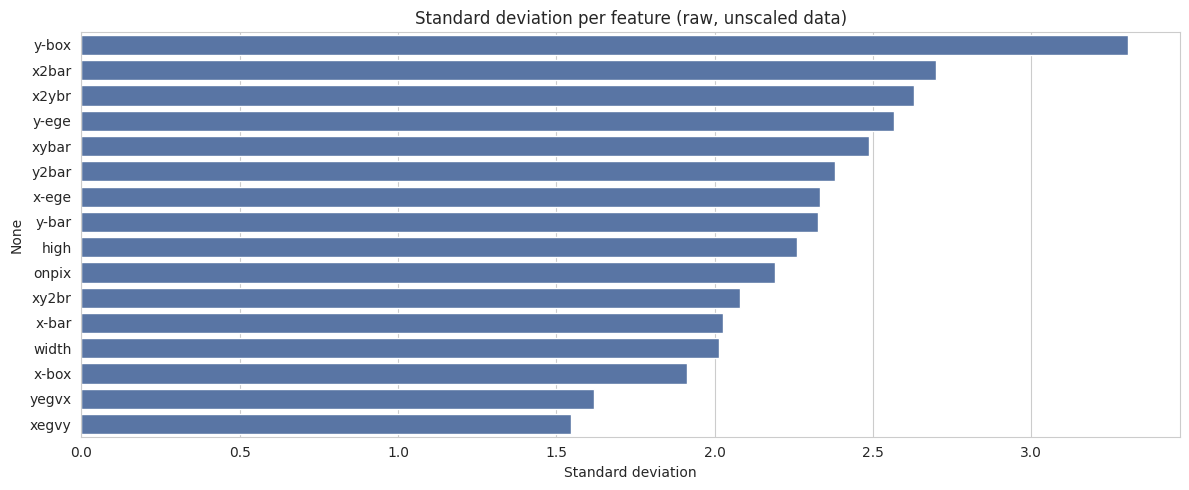

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))
stds = df[feature_cols].std().sort_values(ascending=False)
sns.barplot(x=stds.values, y=stds.index, color='#4C72B0', ax=ax)
ax.set_title('Standard deviation per feature (raw, unscaled data)')
ax.set_xlabel('Standard deviation')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_feature_std_raw.png', dpi=110)
plt.show()


**Interpretation:** The spread of `std` values across the 16 features (roughly from ~2.5 up to
~4.5 in this chart) confirms that even though every feature shares the same nominal 0–15 range, they
are not equally "spread out" within it. A feature like `xy2br` would therefore have disproportionate
influence in any Euclidean-distance calculation compared to a tighter feature like `x-box`, which is
exactly the imbalance that scaling is designed to correct.


## 4. Implementation: StandardScaler vs. MinMaxScaler


In [3]:
standard_scaler = StandardScaler()
df_standard_scaled = df.copy()
df_standard_scaled[feature_cols] = standard_scaler.fit_transform(df[feature_cols])

minmax_scaler = MinMaxScaler()
df_minmax_scaled = df.copy()
df_minmax_scaled[feature_cols] = minmax_scaler.fit_transform(df[feature_cols])

print("After StandardScaler (mean ~ 0, std ~ 1):")
print(df_standard_scaled[feature_cols].agg(['mean', 'std']).T.round(3))

print("\nAfter MinMaxScaler (min = 0, max = 1):")
print(df_minmax_scaled[feature_cols].agg(['min', 'max']).T.round(3))


After StandardScaler (mean ~ 0, std ~ 1):
       mean  std
x-box  -0.0  1.0
y-box   0.0  1.0
width  -0.0  1.0
high    0.0  1.0
onpix  -0.0  1.0
x-bar   0.0  1.0
y-bar   0.0  1.0
x2bar   0.0  1.0
y2bar  -0.0  1.0
xybar   0.0  1.0
x2ybr   0.0  1.0
xy2br  -0.0  1.0
x-ege  -0.0  1.0
xegvy  -0.0  1.0
y-ege   0.0  1.0
yegvx   0.0  1.0

After MinMaxScaler (min = 0, max = 1):
       min  max
x-box  0.0  1.0
y-box  0.0  1.0
width  0.0  1.0
high   0.0  1.0
onpix  0.0  1.0
x-bar  0.0  1.0
y-bar  0.0  1.0
x2bar  0.0  1.0
y2bar  0.0  1.0
xybar  0.0  1.0
x2ybr  0.0  1.0
xy2br  0.0  1.0
x-ege  0.0  1.0
xegvy  0.0  1.0
y-ege  0.0  1.0
yegvx  0.0  1.0


## 5. EDA Visualization: Distribution Before vs. After Scaling


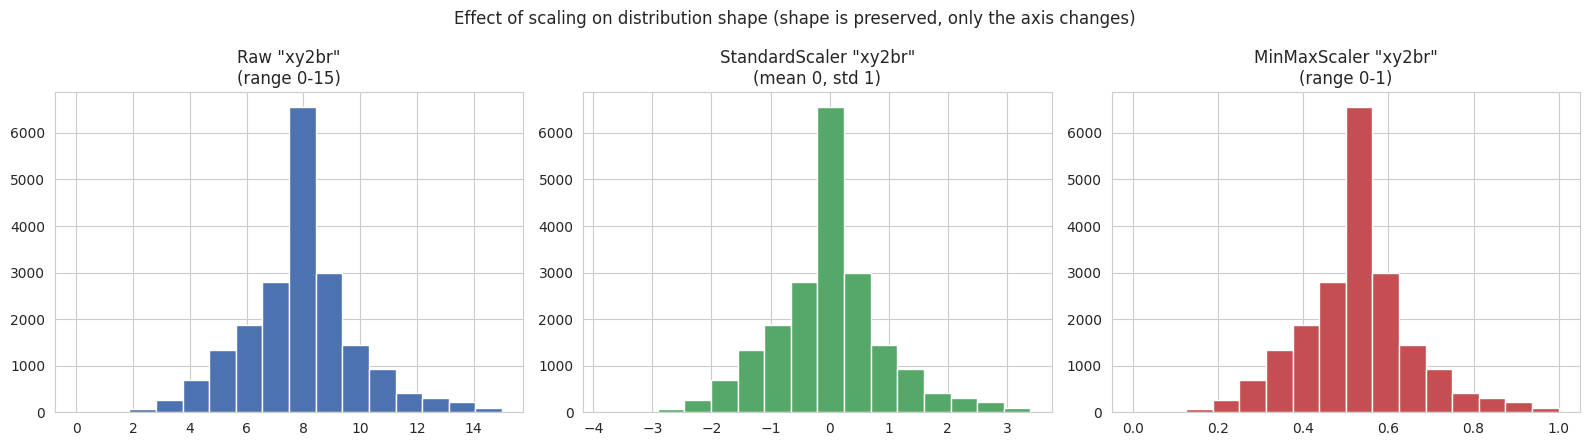

In [4]:
feature_to_check = 'xy2br'
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(df[feature_to_check], bins=16, color='#4C72B0')
axes[0].set_title(f'Raw "{feature_to_check}"\n(range 0-15)')

axes[1].hist(df_standard_scaled[feature_to_check], bins=16, color='#55A868')
axes[1].set_title(f'StandardScaler "{feature_to_check}"\n(mean 0, std 1)')

axes[2].hist(df_minmax_scaled[feature_to_check], bins=16, color='#C44E52')
axes[2].set_title(f'MinMaxScaler "{feature_to_check}"\n(range 0-1)')

plt.suptitle('Effect of scaling on distribution shape (shape is preserved, only the axis changes)')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_scaling_comparison.png', dpi=110)
plt.show()


**Interpretation:** Scaling changes the numeric axis but **not the shape** of the distribution
— the histogram of `xy2br` looks identical up to relabelled axis ticks in all three panels. This is
an important sanity check: scaling should never distort the relative relationships within a feature,
only rescale its units so that it is comparable to the other 15 features.


## 6. Verifying Correlation Structure Is Preserved


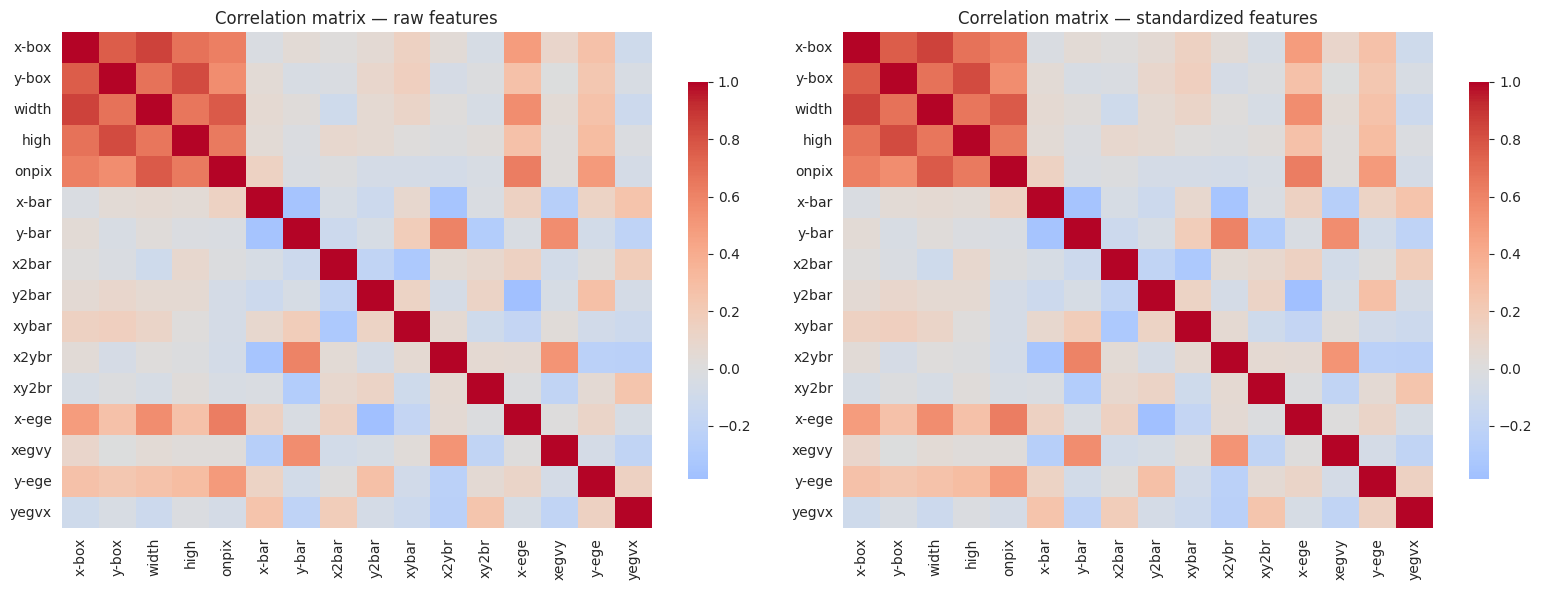

Maximum absolute difference between the two correlation matrices: 0.0000000000


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df[feature_cols].corr(), cmap='coolwarm', center=0, ax=axes[0],
            cbar_kws={'shrink': 0.8})
axes[0].set_title('Correlation matrix — raw features')

sns.heatmap(df_standard_scaled[feature_cols].corr(), cmap='coolwarm', center=0, ax=axes[1],
            cbar_kws={'shrink': 0.8})
axes[1].set_title('Correlation matrix — standardized features')

plt.tight_layout()
plt.savefig('../results/eda_visualizations/almeida_correlation_before_after.png', dpi=110)
plt.show()

max_diff = np.abs(df[feature_cols].corr().values - df_standard_scaled[feature_cols].corr().values).max()
print(f"Maximum absolute difference between the two correlation matrices: {max_diff:.10f}")


**Interpretation:** The two correlation matrices are numerically identical (the maximum
difference is effectively zero, down to floating-point rounding). This confirms scaling only changes
each feature's units, not the relationships *between* features — a useful check before we hand the
scaled data to Muhunthan R.'s correlation-based feature-selection step.


## 7. Conclusion

- The 16 features share a nominal 0–15 range but differ meaningfully in spread (standard deviation),
  which would bias distance-based algorithms and PCA if left unscaled.
- Both `StandardScaler` and `MinMaxScaler` preserve distribution shape and inter-feature correlation;
  they only change the numeric units.
- **Decision:** the group pipeline will use **`StandardScaler`**, since it is the standard choice
  ahead of PCA (Muhunthan R.) and works well for the SVM baseline planned for Progress Review II.
